In [91]:
# Import packages
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from scipy import stats

In [34]:
df_change_my_view = pd.read_csv('./data/data_full_story.csv')
df_change_my_view

,name,story_score,agency_score,event_score,world_score,suspense_score,surprise_score,curiosity_score
0,t1_c95k50u,0.000000,1.000000,1.000000,1.000000,2.75,2.25,1.75
1,t1_c95mz3n,0.857143,4.000000,5.000000,1.000000,2.75,2.75,3.25
2,t1_c95l4my,0.857143,4.000000,4.000000,1.000000,2.75,3.25,3.50
3,t1_c95mcms,0.857143,5.000000,5.000000,1.000000,3.25,4.00,2.50
4,t3_1aenyc,1.000000,5.000000,5.000000,3.666667,2.75,3.50,3.75
...,...,...,...,...,...,...,...,...
615,t1_cauc7tb,0.000000,1.000000,1.000000,1.000000,2.50,2.75,2.25
616,t1_caue431,0.000000,1.000000,1.000000,1.000000,1.00,1.50,1.50
617,t1_ck496qz,0.571429,2.666667,2.666667,1.000000,2.50,2.75,3.25
618,t1_chkfbo3,0.857143,5.000000,3.666667,3.333333,1.75,2.00,2.75


#### 2. Scatterplots of the Data

In [35]:
independent_variables = ['agency_score', 'event_score', 'world_score', 'suspense_score', 'surprise_score', 'curiosity_score']

In [81]:
def scatter(independent_variables):
    """
    Plots 6 scatter plots of the effect of the story features on the story score.

    Parameter:
        independent_variables: List of independent variables.
    Return:
        6 scatter plots.
    """
    row = 0
    col = 0
    # Loop over the independent variables
    for independent_variable in independent_variables:
        # Plot a scatter plot
        sns.scatterplot(x=independent_variable, y='story_score', data=df_change_my_view, ax=axes[row, col]).set_title(f'Effect of {re.sub('_', ' ', independent_variable).title()} on Story Score')

        # Check where the histogram is going to be plotted
        if col < 3:
            col += 1
        if (col == 3) and (row == 0):
            col = 0
            row = 1

    # Plot scatterplots
    plt.tight_layout()
    return plt.show()

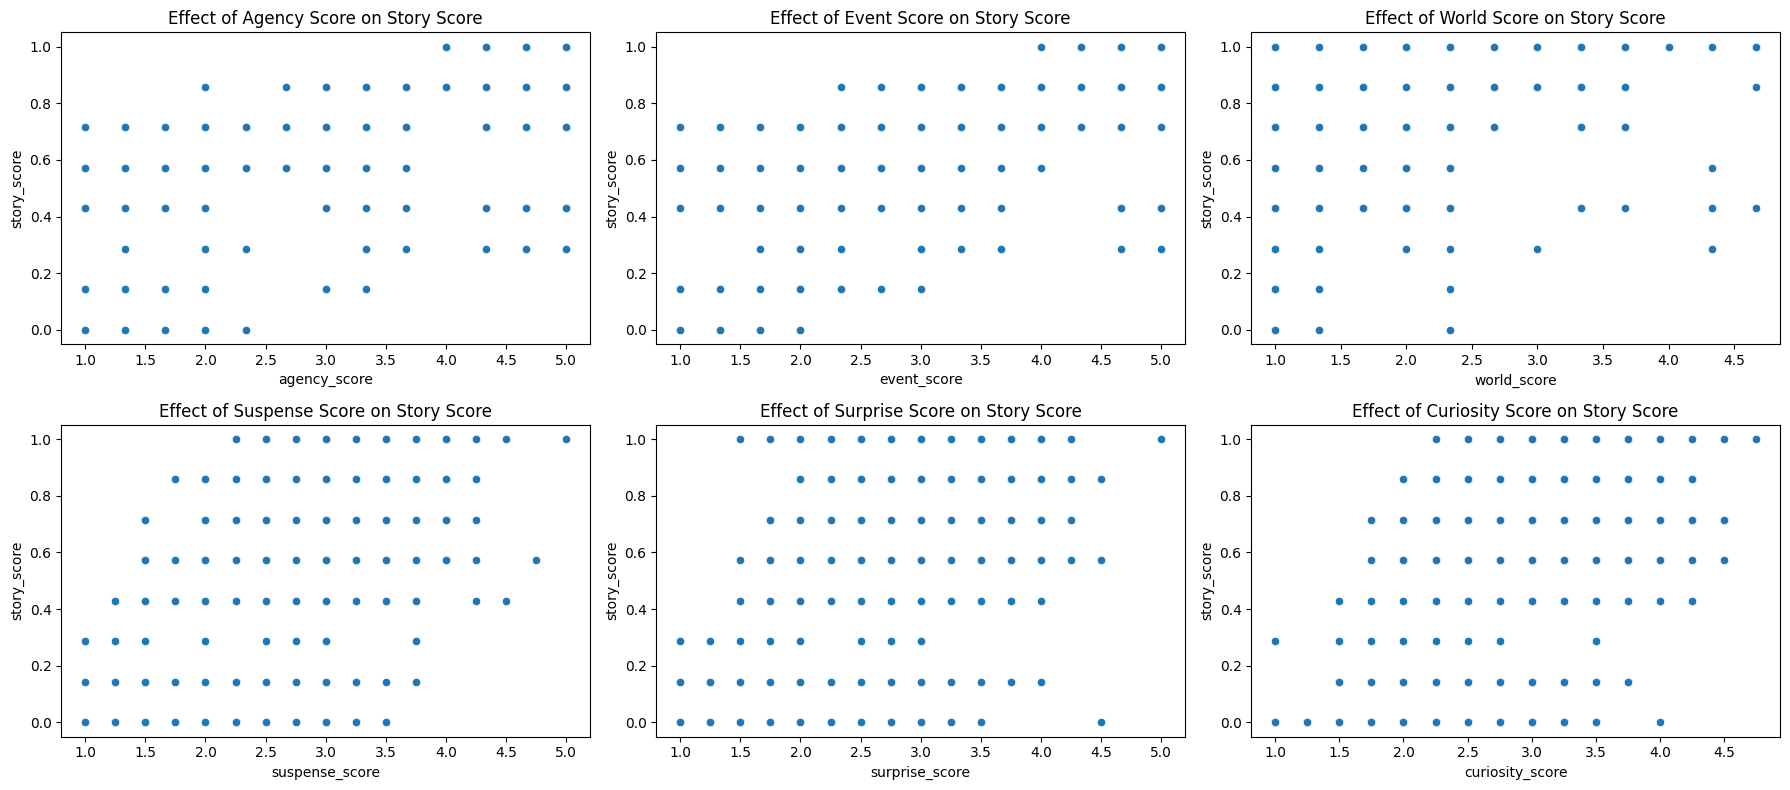

In [82]:
# Create 6 scatterplots
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
scatter(independent_variables)

### 3 - 5. Simple Linear Regression

Simple Linear Regression

agency_score:
Intercept: 0.024369675050673445
Slope:     [0.18627994]


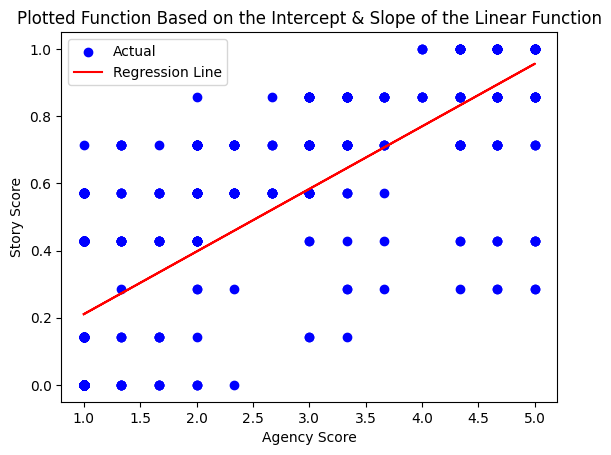

R-squared Score: 0.580823110283913

event_score:
Intercept: 0.020186836862851998
Slope:     [0.19334794]


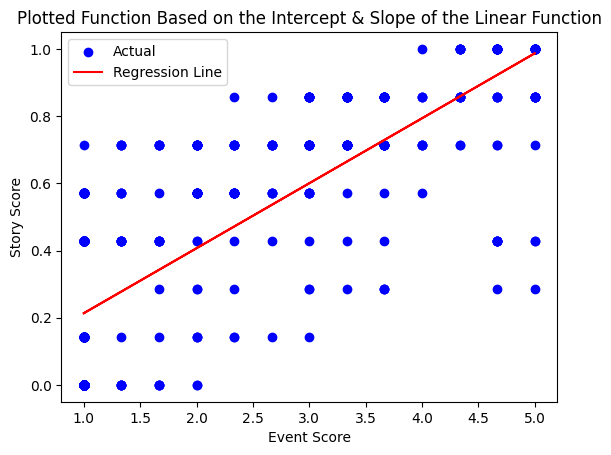

R-squared Score: 0.5971390119224571

world_score:
Intercept: 0.14541022807542575
Slope:     [0.20197245]


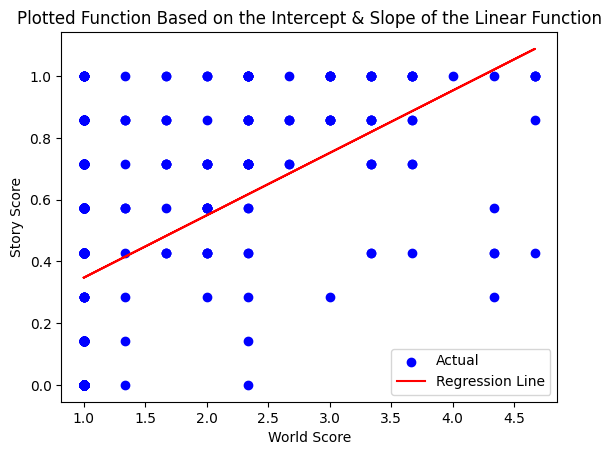

R-squared Score: 0.20441831933988508

suspense_score:
Intercept: -0.21450119998638417
Slope:     [0.25757107]


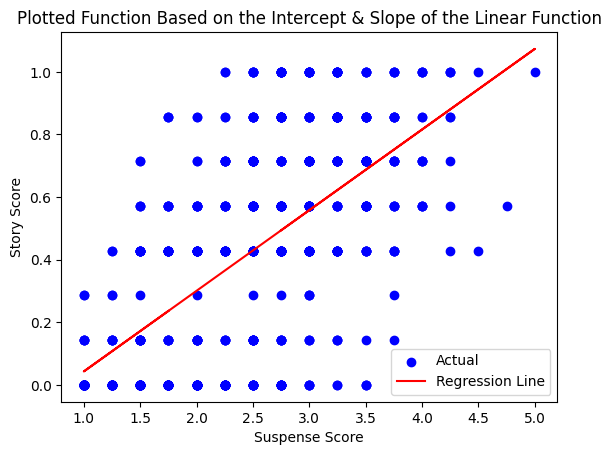

R-squared Score: 0.4214307264112034

surprise_score:
Intercept: -0.20140768303424395
Slope:     [0.23856646]


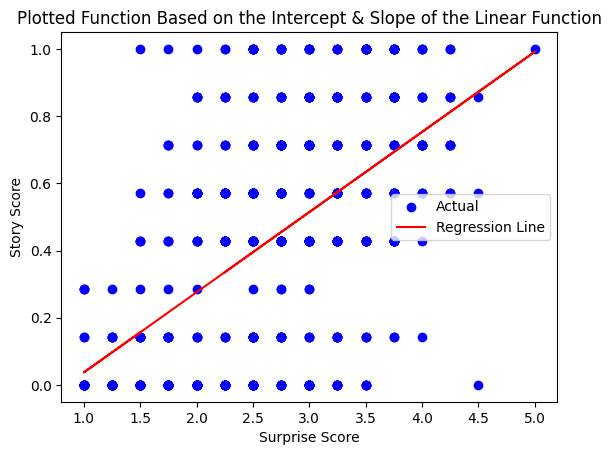

R-squared Score: 0.3427290841563504

curiosity_score:
Intercept: -0.31947316124492453
Slope:     [0.26549191]


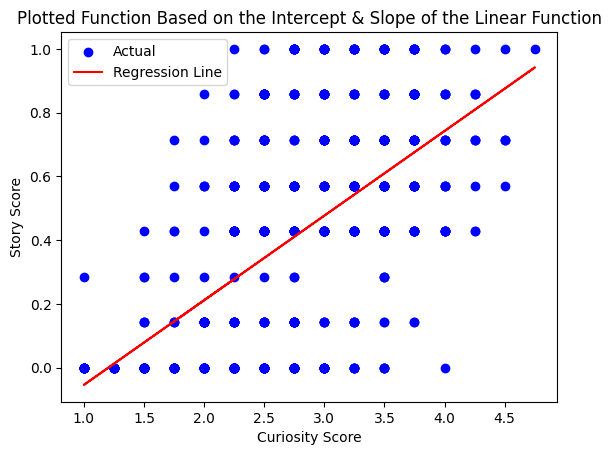

R-squared Score: 0.36142282050508


In [94]:
print("Simple Linear Regression")
for independent_variable in independent_variables:
    # Assign independent variable
    X = df_change_my_view[[independent_variable]]
    # Assign dependent variable
    y = df_change_my_view['story_score']

    # Create a Linear Regression model
    lr = LinearRegression().fit(X, y)

    # Print the slope and intercept
    print(f"""\n{independent_variable}:
Intercept: {lr.intercept_}
Slope:     {lr.coef_}""")

    # Predict the story score for the test set
    y_pred = lr.predict(X)

    # Plot the function based on the intercept and slope
    plt.scatter(X, y, color='blue', label='Actual') # Plot the actual data points
    plt.plot(X, y_pred, color='red', label='Regression Line') # Plot the regression line
    plt.xlabel(re.sub('_', ' ', independent_variable).title())
    plt.ylabel('Story Score')
    plt.title('Plotted Function Based on the Intercept & Slope of the Linear Function')
    plt.legend()
    plt.show()
    
    # Calculate the r^2 score
    r2 = r2_score(y, y_pred)
    print(f"R-squared Score: {r2}")

### 6 & 7. Residuals

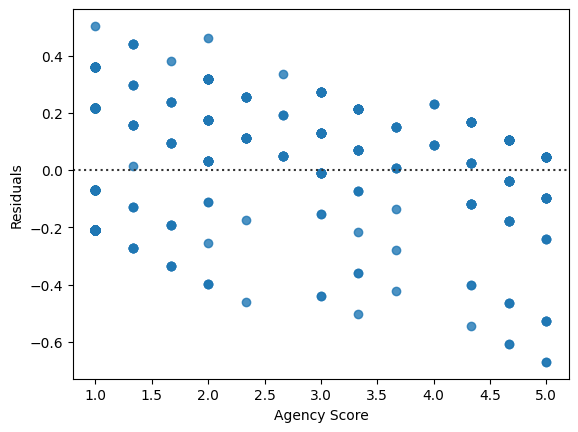

ShapiroResult(statistic=np.float64(0.8947897563944909), pvalue=np.float64(7.291566396604978e-08))


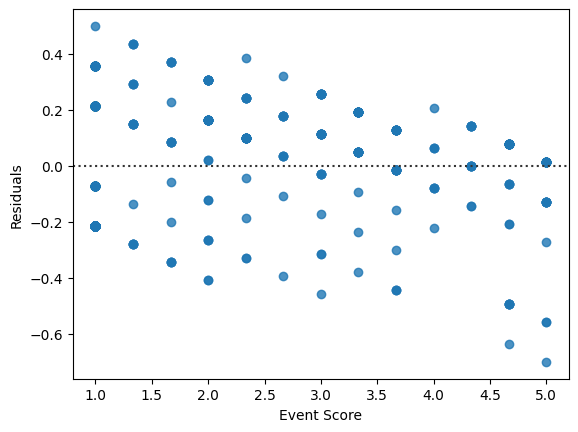

ShapiroResult(statistic=np.float64(0.9057540001991112), pvalue=np.float64(2.7109011480837825e-07))


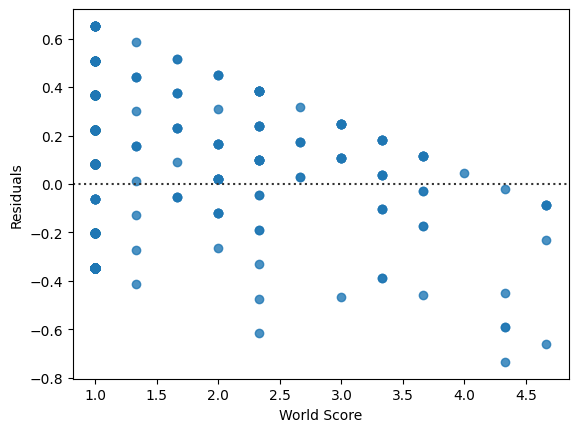

ShapiroResult(statistic=np.float64(0.888128502839876), pvalue=np.float64(3.416127708675586e-08))


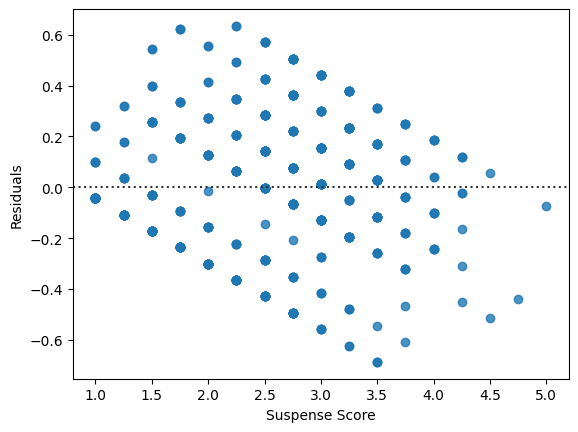

ShapiroResult(statistic=np.float64(0.9741546759352515), pvalue=np.float64(0.01755606489657929))


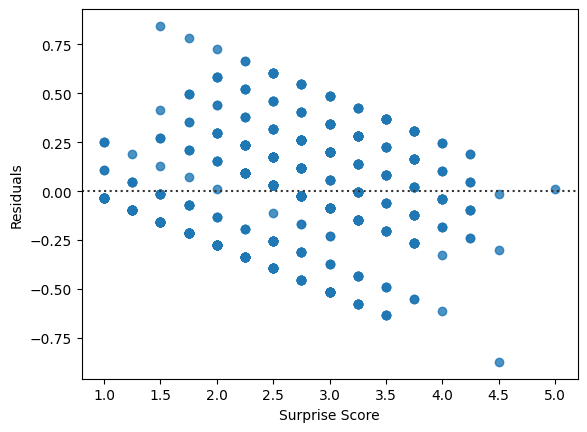

ShapiroResult(statistic=np.float64(0.9887561729227), pvalue=np.float64(0.40552581615679384))


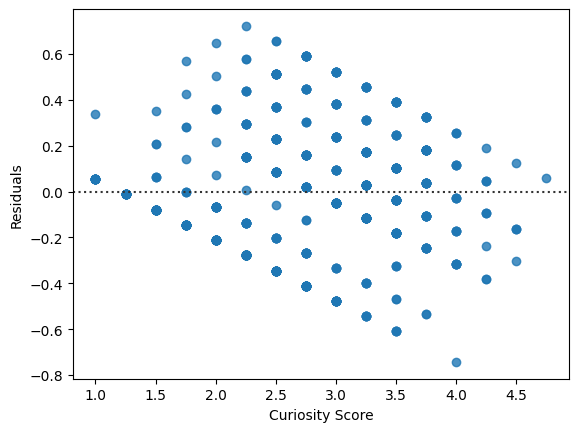

ShapiroResult(statistic=np.float64(0.9680844415688408), pvalue=np.float64(0.004932309414574595))


In [53]:
for independent_variable in independent_variables:
    sns.residplot(x=independent_variable, y='story_score', data=df_change_my_view)
    plt.xlabel(re.sub('_', ' ', independent_variable).title())
    plt.ylabel("Residuals")
    plt.show()

    # Assign independent variable
    x = df_change_my_view[[independent_variable]]
    # Assign dependent variable
    y = df_change_my_view['story_score']

    # Create a Linear Regression model
    lr = LinearRegression()
    lr.fit(x, y)
    
    # Calculate the residuals
    X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
    results = lr.predict(X_test)
    residuals = results - y_test
    shapiro_test = stats.shapiro(residuals)
    print(shapiro_test)